# Pipeline EDA dan Modeling LSTM/BiLSTM untuk Prediksi Kepatuhan Pengobatan Pasien

Notebook ini menggabungkan dua bagian utama:

## Notebook 1: EDA Dataset
- cek struktur data
- cek missing value
- cek distribusi `ADHERENCE`
- cek jumlah refill per pasien
- cek distribusi tanggal refill
- cek imbalance label

## Notebook 2: Modeling Pipeline
- cleaning
- agregasi `patient-date`
- pembentukan sequence
- train/validation/test split
- baseline model
- LSTM
- BiLSTM
- evaluasi
- XAI awal

> Catatan penelitian: pipeline ini disusun untuk dataset **Dataset for analysing medication adherence among diabetes and hypertension patients: Patient-level and medication refill data**. Dataset mentah berbentuk claim/refill-level, sehingga perlu diubah terlebih dahulu menjadi data sekuensial per pasien agar sesuai untuk LSTM/BiLSTM.

# 0. Setup Environment
Bagian ini memuat library utama yang digunakan. Notebook ini menggunakan:
- `pandas` dan `numpy` untuk pengolahan data
- `matplotlib` untuk visualisasi
- `scikit-learn` untuk baseline model dan evaluasi
- `PyTorch` untuk LSTM dan BiLSTM

In [2]:
import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")

try:
    import torch
    import torch.nn as nn
    from torch.utils.data import Dataset, DataLoader
    TORCH_AVAILABLE = True
except Exception as e:
    TORCH_AVAILABLE = False
    print("PyTorch belum tersedia pada environment ini:", e)

RANDOM_STATE = 42

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    if TORCH_AVAILABLE:
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(RANDOM_STATE)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

print("Torch available:", TORCH_AVAILABLE)
if TORCH_AVAILABLE:
    print("Torch version:", torch.__version__)
    print("Device:", "cuda" if torch.cuda.is_available() else "cpu")

Torch available: True
Torch version: 2.12.0
Device: cpu


# 1. Konfigurasi Penelitian

Silakan sesuaikan konfigurasi di bawah ini sesuai kebutuhan eksperimen.

## Label target
Ada dua opsi label yang umum digunakan:

1. **Standard non-adherence**
   - `target = 1` jika `ADHERENCE < 9`
   - `target = 0` jika `ADHERENCE >= 9`

2. **Severe non-adherence**
   - `target = 1` jika `ADHERENCE <= 3`
   - `target = 0` jika `ADHERENCE > 3`

Untuk penelitian utama Anda, mode `standard` lebih dekat dengan definisi umum adherence berbasis 75% atau minimal 9 bulan dari 12 bulan. Mode `severe` bisa digunakan sebagai eksperimen tambahan untuk melihat kasus ketidakpatuhan berat dan imbalance yang lebih jelas.

In [3]:
# ==========================
# PATH DATASET
# ==========================
DATA_DIR = Path("dataset")

# Notebook akan otomatis mencoba menemukan file diabetes dan HTN.
DIABETES_PATH_CANDIDATES = [
    DATA_DIR / "Diabetes Adherence Data(1).csv",
    DATA_DIR / "Diabetes Adherence Data.csv",
]

HTN_PATH_CANDIDATES = [
    DATA_DIR / "HTN Adherence Data.csv",
    DATA_DIR / "HTN Adherence Data(1).csv",
]

def first_existing(paths):
    for p in paths:
        if p.exists():
            return p
    return None

DIABETES_PATH = first_existing(DIABETES_PATH_CANDIDATES)
HTN_PATH = first_existing(HTN_PATH_CANDIDATES)

print("Diabetes path:", DIABETES_PATH)
print("HTN path     :", HTN_PATH)

# ==========================
# DATASET YANG DIGUNAKAN
# ==========================
# Pilihan:
# - "diabetes" : hanya dataset diabetes
# - "htn"      : hanya dataset hipertensi
# - "combined" : gabungan diabetes dan hipertensi, jika kedua file tersedia
DATASET_MODE = "diabetes"

# ==========================
# TARGET LABEL
# ==========================
# Pilihan:
# - "standard" : target = 1 jika ADHERENCE < 9
# - "severe"   : target = 1 jika ADHERENCE <= SEVERE_THRESHOLD
LABEL_MODE = "standard"
SEVERE_THRESHOLD = 3

# ==========================
# SEQUENCE SETTING
# ==========================
# MAX_SEQ_LEN = jumlah event refill yang digunakan sebagai input model
# SEQUENCE_MODE:
# - "first": ambil refill awal, cocok untuk prediksi prospektif
# - "last" : ambil refill terakhir, cocok untuk klasifikasi retrospektif
MAX_SEQ_LEN = 6
SEQUENCE_MODE = "first"

# ==========================
# MODEL SETTING
# ==========================
BATCH_SIZE = 64
EPOCHS = 20
LEARNING_RATE = 1e-3
HIDDEN_SIZE = 64
NUM_LAYERS = 1
DROPOUT = 0.2
USE_CLASS_WEIGHT = True
USE_FOCAL_LOSS = False
FOCAL_GAMMA = 2.0

print("Konfigurasi selesai.")

Diabetes path: dataset/Diabetes Adherence Data.csv
HTN path     : dataset/HTN Adherence Data.csv
Konfigurasi selesai.


# Notebook 1: EDA Dataset
Bagian ini bertujuan memahami karakteristik awal dataset sebelum masuk ke modeling.

## 2. Load Dataset
Bagian ini membaca dataset Diabetes, HTN, atau gabungan keduanya.

In [4]:
def load_single_dataset(path, disease_label):
    if path is None:
        raise FileNotFoundError(f"File untuk {disease_label} tidak ditemukan.")
    df = pd.read_csv(path)
    df["disease_type"] = disease_label
    return df

if DATASET_MODE == "diabetes":
    df_raw = load_single_dataset(DIABETES_PATH, "diabetes")
elif DATASET_MODE == "htn":
    df_raw = load_single_dataset(HTN_PATH, "htn")
elif DATASET_MODE == "combined":
    dfs = []
    if DIABETES_PATH is not None:
        dfs.append(load_single_dataset(DIABETES_PATH, "diabetes"))
    if HTN_PATH is not None:
        dfs.append(load_single_dataset(HTN_PATH, "htn"))
    if not dfs:
        raise FileNotFoundError("Tidak ada file Diabetes atau HTN yang ditemukan.")
    df_raw = pd.concat(dfs, ignore_index=True)
else:
    raise ValueError("DATASET_MODE harus 'diabetes', 'htn', atau 'combined'.")

print("Shape dataset:", df_raw.shape)
display(df_raw.head())

Shape dataset: (52616, 42)


,MEMBER,INO,PZTIQNT NZXQ,ADHERENCE,GENDER,PRACTICE NO,DIS,PROVIDER,AS AT NETWORKS,REFERRING PRACTICE,PAYER NAME,INV REF,SERVICE DATE,ASSESS DATE,DATE RECEIVED,CLM CODE,CODE DESCRIPTION,UNITS,SCRIPT CODE,AMOUNT CLAIMED,PAID FROM RISK AMT,PAID FROM THRESHHOLD,PAID FROM SAVINGS,RECOVERY AMOUNT,TOTAL AMOUNT PAID,TARIFF,CO-PAY,PAY TO,REJ,REV,AUTH NO,DL,CLAIM NO,CLAIM LINE NO,DUPLICATE CLAIM,DUPLICATE CLAIM LINE,OPTION NAME,PAPER/EDI,ASSESSOR NAME,BIRTHDATE,CURRENT AGE,disease_type
0,98788489,0,XS TZFZDZWZ NYZPIXBI,2,F,860662,60,81302 PLUS TWO PHARMACY,NaN,847321.0,AFRICA UNIVERSITY STUDENTS,2921164,7/9/2022,7/9/2022,7/9/2022,21249,RANOPHAGE (METFORMIN HYDROCHLORIDE MODIFIED RE...,30,NaN,6800.00,6800.00,0,0,0.0,6800.00,6800.00,0,P,N,N,NaN,N,3285628,7248261,NaN,NaN,STUDYMATE PRIVATE,EDI,CIMAS_HEALTH263 ADMIN,11/7/1999,24,diabetes
1,98795328,0,XR TSITSIKZYI XUDOTI,7,M,877344,60,92398 CIMAS HCC MUTARE PHARMACY,CIMAS PHARMACIES (2123),866776.0,GUARD ALERT (PVT) LTD,80209,4/7/2022,4/7/2022,4/7/2022,21272,METFORMIN TABLETS 500MG 500S,90,NaN,2654.98,2654.98,0,0,0.0,2654.98,2654.98,0,P,N,N,27106.0,N,2760001,6299632,NaN,NaN,ICARE,EDI,CIMAS_HEALTH263 ADMIN,3/7/1970,53,diabetes
2,98795328,0,XR TSITSIKZYI XUDOTI,7,M,877344,60,92398 CIMAS HCC MUTARE PHARMACY,CIMAS PHARMACIES (2123),866776.0,GUARD ALERT (PVT) LTD,80209,4/7/2022,4/7/2022,4/7/2022,21006,GLIMULIN - 2 (GLIMEPIRIDE) 2MG 30S,120,NaN,40914.28,40914.28,0,0,0.0,40914.28,40914.28,0,P,N,N,27106.0,N,2760001,6299633,NaN,NaN,ICARE,EDI,CIMAS_HEALTH263 ADMIN,3/7/1970,53,diabetes
3,98795328,0,XR TSITSIKZYI XUDOTI,7,M,877344,60,92398 CIMAS HCC MUTARE PHARMACY,CIMAS PHARMACIES (2123),866776.0,GUARD ALERT (PVT) LTD,82681,6/8/2022,6/8/2022,6/8/2022,21006,GLIMULIN - 2 (GLIMEPIRIDE) 2MG 30S,120,NaN,55643.20,55643.20,0,0,0.0,55643.20,55643.20,0,P,N,N,27106.0,N,3052168,6825161,NaN,NaN,ICARE,EDI,CIMAS_HEALTH263 ADMIN,3/7/1970,53,diabetes
4,98795328,0,XR TSITSIKZYI XUDOTI,7,M,877344,60,92398 CIMAS HCC MUTARE PHARMACY,CIMAS PHARMACIES (2123),866776.0,GUARD ALERT (PVT) LTD,82681,6/8/2022,6/8/2022,6/8/2022,21272,METFORMIN TABLETS 500MG 500S,90,NaN,3573.25,3573.25,0,0,0.0,3573.25,3573.25,0,P,N,N,27106.0,N,3052168,6825160,NaN,NaN,ICARE,EDI,CIMAS_HEALTH263 ADMIN,3/7/1970,53,diabetes


## 3. Cek Struktur Data
Bagian ini melihat kolom, tipe data, jumlah baris, dan contoh nilai.

In [5]:
print("Jumlah baris:", df_raw.shape[0])
print("Jumlah kolom:", df_raw.shape[1])

display(pd.DataFrame({
    "column": df_raw.columns,
    "dtype": [df_raw[c].dtype for c in df_raw.columns],
    "n_unique": [df_raw[c].nunique(dropna=True) for c in df_raw.columns],
    "sample_values": [df_raw[c].dropna().astype(str).unique()[:5] for c in df_raw.columns]
}))

Jumlah baris: 52616
Jumlah kolom: 42


,column,dtype,n_unique,sample_values
0,MEMBER,int64,4444,"[98788489, 98795328, 98799665, 98889992, 98882..."
1,INO,int64,15,"[0, 1, 2, 3, 8]"
2,PZTIQNT NZXQ,str,4836,"[XS TZFZDZWZ NYZPIXBI, XR TSITSIKZYI XUDOTI, X..."
3,ADHERENCE,int64,13,"[2, 7, 3, 9, 4]"
4,GENDER,str,2,"[F, M]"
5,PRACTICE NO,int64,276,"[860662, 877344, 934917, 1032720, 877379]"
6,DIS,int64,4,"[60, 203, 999, 14]"
7,PROVIDER,str,276,"[81302 PLUS TWO PHARMACY, 92398 CIMAS HCC MUT..."
8,AS AT NETWORKS,str,3,"[CIMAS PHARMACIES (2123), LICENSED GP PROVIDER..."
9,REFERRING PRACTICE,float64,588,"[847321.0, 866776.0, 842605.0, 889458.0, 85609..."


In [6]:
print("Info dataset:")
df_raw.info()

Info dataset:


<class 'pandas.DataFrame'>
RangeIndex: 52616 entries, 0 to 52615
Data columns (total 42 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   MEMBER                52616 non-null  int64  
 1   INO                   52616 non-null  int64  
 2   PZTIQNT NZXQ          52616 non-null  str    
 3   ADHERENCE             52616 non-null  int64  
 4   GENDER                52616 non-null  str    
 5   PRACTICE NO           52616 non-null  int64  
 6   DIS                   52616 non-null  int64  
 7   PROVIDER              52616 non-null  str    
 8   AS AT NETWORKS        41358 non-null  str    
 9   REFERRING PRACTICE    51754 non-null  float64
 10  PAYER NAME            52616 non-null  str    
 11  INV REF               52616 non-null  str    
 12  SERVICE DATE          52616 non-null  str    
 13  ASSESS DATE           52616 non-null  str    
 14  DATE RECEIVED         52616 non-null  str    
 15  CLM CODE              52616 no

## 4. Cek Missing Value
Bagian ini menghitung jumlah dan persentase missing value pada setiap kolom.

,missing_count,missing_percent
SCRIPT CODE,52616,100.000000
DUPLICATE CLAIM LINE,52616,100.000000
DUPLICATE CLAIM,52616,100.000000
AUTH NO,13388,25.444732
AS AT NETWORKS,11258,21.396533
REFERRING PRACTICE,862,1.638285
MEMBER,0,0.000000
DL,0,0.000000
TARIFF,0,0.000000
CO-PAY,0,0.000000


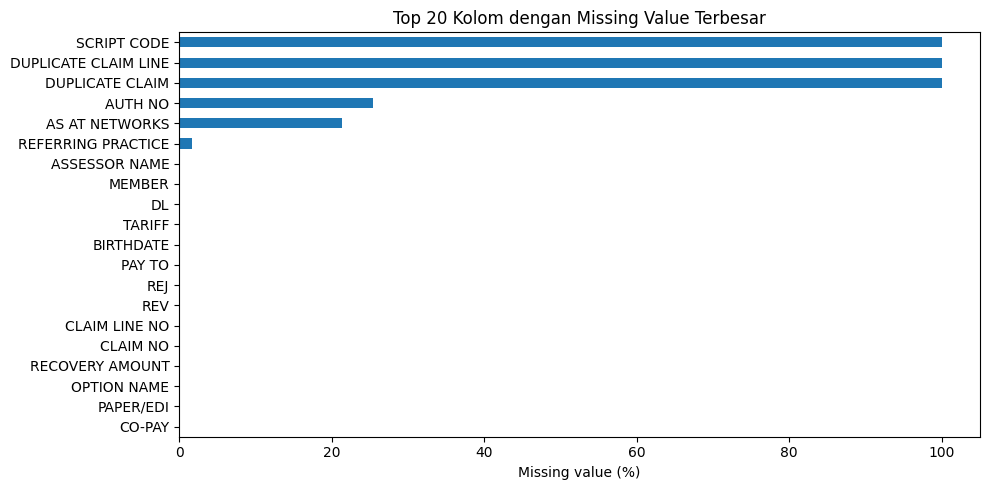

In [7]:
missing_summary = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_percent": df_raw.isna().mean() * 100
}).sort_values("missing_percent", ascending=False)

display(missing_summary)

plt.figure(figsize=(10, 5))
missing_summary["missing_percent"].head(20).sort_values().plot(kind="barh")
plt.xlabel("Missing value (%)")
plt.title("Top 20 Kolom dengan Missing Value Terbesar")
plt.tight_layout()
plt.show()

## 5. Cleaning Ringan untuk EDA
Pada tahap ini dilakukan:
- parsing kolom tanggal
- pembuatan `patient_id`
- konversi `ADHERENCE` menjadi numerik

Catatan: `patient_id` dibuat dari gabungan beberapa kolom agar lebih spesifik daripada hanya `MEMBER`.

In [8]:
DATE_COLUMNS = ["SERVICE DATE", "ASSESS DATE", "DATE RECEIVED", "BIRTHDATE"]

def make_patient_id(df):
    # Gunakan kolom yang tersedia. Beberapa nama kolom terlihat teracak/tersamarkan pada dataset.
    candidate_cols = ["MEMBER", "INO", "PZTIQNT NZXQ"]
    available_cols = [c for c in candidate_cols if c in df.columns]

    if len(available_cols) == 0:
        raise ValueError("Kolom identitas pasien tidak ditemukan. Cek kembali nama kolom ID.")

    pid = df[available_cols].astype(str).agg("_".join, axis=1)
    return pid

def basic_cleaning(df):
    df = df.copy()

    for col in DATE_COLUMNS:
        if col in df.columns:
            df[col] = pd.to_datetime(df[col], errors="coerce")

    if "ADHERENCE" in df.columns:
        df["ADHERENCE"] = pd.to_numeric(df["ADHERENCE"], errors="coerce")

    df["patient_id"] = make_patient_id(df)

    return df

df = basic_cleaning(df_raw)

print("Shape setelah basic cleaning:", df.shape)
display(df.head())

Shape setelah basic cleaning: (52616, 43)


,MEMBER,INO,PZTIQNT NZXQ,ADHERENCE,GENDER,PRACTICE NO,DIS,PROVIDER,AS AT NETWORKS,REFERRING PRACTICE,PAYER NAME,INV REF,SERVICE DATE,ASSESS DATE,DATE RECEIVED,CLM CODE,CODE DESCRIPTION,UNITS,SCRIPT CODE,AMOUNT CLAIMED,PAID FROM RISK AMT,PAID FROM THRESHHOLD,PAID FROM SAVINGS,RECOVERY AMOUNT,TOTAL AMOUNT PAID,TARIFF,CO-PAY,PAY TO,REJ,REV,AUTH NO,DL,CLAIM NO,CLAIM LINE NO,DUPLICATE CLAIM,DUPLICATE CLAIM LINE,OPTION NAME,PAPER/EDI,ASSESSOR NAME,BIRTHDATE,CURRENT AGE,disease_type,patient_id
0,98788489,0,XS TZFZDZWZ NYZPIXBI,2,F,860662,60,81302 PLUS TWO PHARMACY,NaN,847321.0,AFRICA UNIVERSITY STUDENTS,2921164,2022-07-09,2022-07-09,2022-07-09,21249,RANOPHAGE (METFORMIN HYDROCHLORIDE MODIFIED RE...,30,NaN,6800.00,6800.00,0,0,0.0,6800.00,6800.00,0,P,N,N,NaN,N,3285628,7248261,NaN,NaN,STUDYMATE PRIVATE,EDI,CIMAS_HEALTH263 ADMIN,1999-11-07,24,diabetes,98788489_0_XS TZFZDZWZ NYZPIXBI
1,98795328,0,XR TSITSIKZYI XUDOTI,7,M,877344,60,92398 CIMAS HCC MUTARE PHARMACY,CIMAS PHARMACIES (2123),866776.0,GUARD ALERT (PVT) LTD,80209,2022-04-07,2022-04-07,2022-04-07,21272,METFORMIN TABLETS 500MG 500S,90,NaN,2654.98,2654.98,0,0,0.0,2654.98,2654.98,0,P,N,N,27106.0,N,2760001,6299632,NaN,NaN,ICARE,EDI,CIMAS_HEALTH263 ADMIN,1970-03-07,53,diabetes,98795328_0_XR TSITSIKZYI XUDOTI
2,98795328,0,XR TSITSIKZYI XUDOTI,7,M,877344,60,92398 CIMAS HCC MUTARE PHARMACY,CIMAS PHARMACIES (2123),866776.0,GUARD ALERT (PVT) LTD,80209,2022-04-07,2022-04-07,2022-04-07,21006,GLIMULIN - 2 (GLIMEPIRIDE) 2MG 30S,120,NaN,40914.28,40914.28,0,0,0.0,40914.28,40914.28,0,P,N,N,27106.0,N,2760001,6299633,NaN,NaN,ICARE,EDI,CIMAS_HEALTH263 ADMIN,1970-03-07,53,diabetes,98795328_0_XR TSITSIKZYI XUDOTI
3,98795328,0,XR TSITSIKZYI XUDOTI,7,M,877344,60,92398 CIMAS HCC MUTARE PHARMACY,CIMAS PHARMACIES (2123),866776.0,GUARD ALERT (PVT) LTD,82681,2022-06-08,2022-06-08,2022-06-08,21006,GLIMULIN - 2 (GLIMEPIRIDE) 2MG 30S,120,NaN,55643.20,55643.20,0,0,0.0,55643.20,55643.20,0,P,N,N,27106.0,N,3052168,6825161,NaN,NaN,ICARE,EDI,CIMAS_HEALTH263 ADMIN,1970-03-07,53,diabetes,98795328_0_XR TSITSIKZYI XUDOTI
4,98795328,0,XR TSITSIKZYI XUDOTI,7,M,877344,60,92398 CIMAS HCC MUTARE PHARMACY,CIMAS PHARMACIES (2123),866776.0,GUARD ALERT (PVT) LTD,82681,2022-06-08,2022-06-08,2022-06-08,21272,METFORMIN TABLETS 500MG 500S,90,NaN,3573.25,3573.25,0,0,0.0,3573.25,3573.25,0,P,N,N,27106.0,N,3052168,6825160,NaN,NaN,ICARE,EDI,CIMAS_HEALTH263 ADMIN,1970-03-07,53,diabetes,98795328_0_XR TSITSIKZYI XUDOTI


## 6. Distribusi `ADHERENCE`
Bagian ini melihat distribusi nilai `ADHERENCE`. Dalam dataset ini, `ADHERENCE` biasanya merepresentasikan jumlah bulan/periode refill yang terpenuhi.

,claim_level_count
ADHERENCE,
1,829
2,846
3,1038
4,1391
5,1911
6,2423
7,3223
8,4592
9,6513


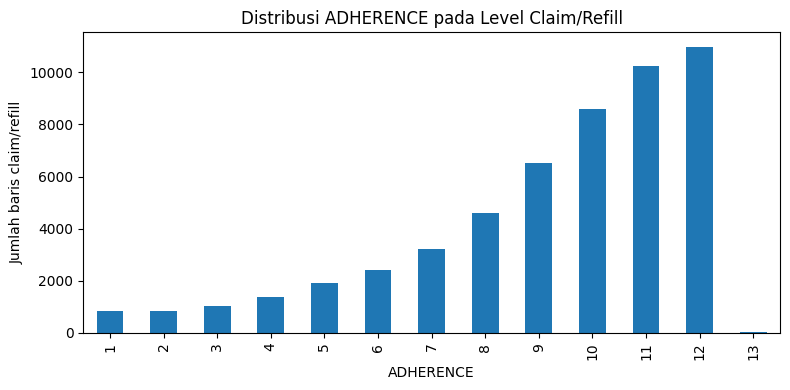

,patient_level_count
ADHERENCE,
1,662
2,322
3,257
4,258
5,265
6,278
7,306
8,380
9,464


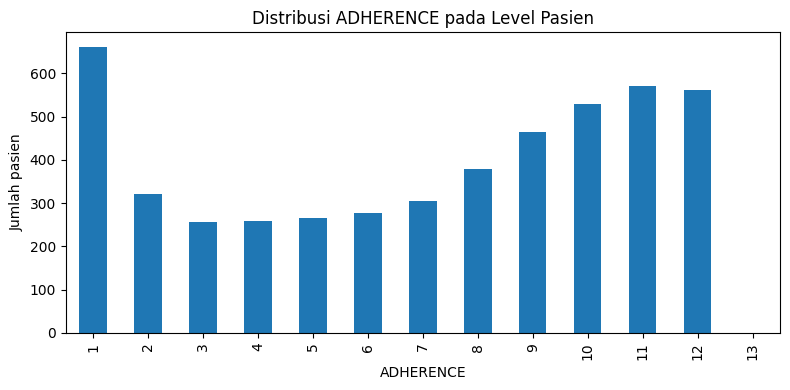

In [9]:
if "ADHERENCE" not in df.columns:
    raise ValueError("Kolom ADHERENCE tidak ditemukan.")

adherence_dist_claim = df["ADHERENCE"].value_counts(dropna=False).sort_index()
display(adherence_dist_claim.rename("claim_level_count").to_frame())

plt.figure(figsize=(8, 4))
adherence_dist_claim.plot(kind="bar")
plt.xlabel("ADHERENCE")
plt.ylabel("Jumlah baris claim/refill")
plt.title("Distribusi ADHERENCE pada Level Claim/Refill")
plt.tight_layout()
plt.show()

# Distribusi patient-level: ambil satu nilai adherence per pasien.
patient_adherence = (
    df.groupby("patient_id", as_index=False)
      .agg(ADHERENCE=("ADHERENCE", "max"))
)

adherence_dist_patient = patient_adherence["ADHERENCE"].value_counts(dropna=False).sort_index()
display(adherence_dist_patient.rename("patient_level_count").to_frame())

plt.figure(figsize=(8, 4))
adherence_dist_patient.plot(kind="bar")
plt.xlabel("ADHERENCE")
plt.ylabel("Jumlah pasien")
plt.title("Distribusi ADHERENCE pada Level Pasien")
plt.tight_layout()
plt.show()

## 7. Cek Jumlah Refill per Pasien
Bagian ini menghitung banyaknya baris claim/refill dan banyaknya tanggal refill unik per pasien.

,patient_id,n_claim_rows,n_service_dates,first_service_date,last_service_date,adherence,followup_days
count,4855,4855.000000,4855.000000,3851,3851,4855.000000,3851.000000
unique,4855,NaN,NaN,NaN,NaN,NaN,NaN
top,92222888_1_XRS TZRISZYI GQTRUDQ NYZXBIYZ,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,10.837487,3.096601,2022-04-03 23:56:38.078421,2022-08-28 04:41:11.669696,6.959217,146.197611
min,NaN,1.000000,0.000000,2021-01-11 00:00:00,2021-01-12 00:00:00,1.000000,0.000000
25%,NaN,4.000000,1.000000,2022-01-10 00:00:00,2022-07-01 00:00:00,3.000000,1.000000
50%,NaN,10.000000,2.000000,2022-03-05 00:00:00,2022-10-06 00:00:00,8.000000,150.000000
75%,NaN,16.000000,5.000000,2022-06-07 00:00:00,2022-12-01 00:00:00,10.000000,246.000000
max,NaN,40.000000,15.000000,2022-12-12 00:00:00,2022-12-12 00:00:00,13.000000,698.000000


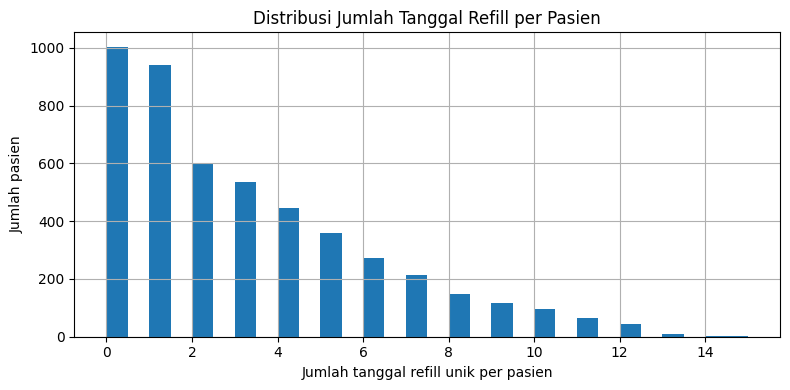

Persentase pasien dengan minimal N tanggal refill:
>= 2 tanggal refill: 2,909 pasien (59.92%)
>= 3 tanggal refill: 2,307 pasien (47.52%)
>= 5 tanggal refill: 1,325 pasien (27.29%)
>= 6 tanggal refill: 967 pasien (19.92%)
>= 9 tanggal refill: 332 pasien (6.84%)
>= 12 tanggal refill: 54 pasien (1.11%)


In [10]:
if "SERVICE DATE" not in df.columns:
    raise ValueError("Kolom SERVICE DATE tidak ditemukan.")

refill_per_patient = (
    df.groupby("patient_id")
      .agg(
          n_claim_rows=("patient_id", "size"),
          n_service_dates=("SERVICE DATE", "nunique"),
          first_service_date=("SERVICE DATE", "min"),
          last_service_date=("SERVICE DATE", "max"),
          adherence=("ADHERENCE", "max")
      )
      .reset_index()
)

refill_per_patient["followup_days"] = (
    refill_per_patient["last_service_date"] - refill_per_patient["first_service_date"]
).dt.days

display(refill_per_patient.describe(include="all"))

plt.figure(figsize=(8, 4))
refill_per_patient["n_service_dates"].hist(bins=30)
plt.xlabel("Jumlah tanggal refill unik per pasien")
plt.ylabel("Jumlah pasien")
plt.title("Distribusi Jumlah Tanggal Refill per Pasien")
plt.tight_layout()
plt.show()

print("Persentase pasien dengan minimal N tanggal refill:")
for n in [2, 3, 5, 6, 9, 12]:
    pct = (refill_per_patient["n_service_dates"] >= n).mean() * 100
    count = (refill_per_patient["n_service_dates"] >= n).sum()
    print(f">= {n} tanggal refill: {count:,} pasien ({pct:.2f}%)")

## 8. Distribusi Tanggal Refill
Bagian ini melihat rentang tanggal dan jumlah refill dari waktu ke waktu.

Tanggal SERVICE DATE minimum: 2021-01-11 00:00:00
Tanggal SERVICE DATE maksimum: 2022-12-12 00:00:00


,SERVICE DATE,n_refill
0,2021-01-11,1
1,2021-01-12,16
2,2021-02-11,2
3,2021-02-12,1
4,2021-03-11,3


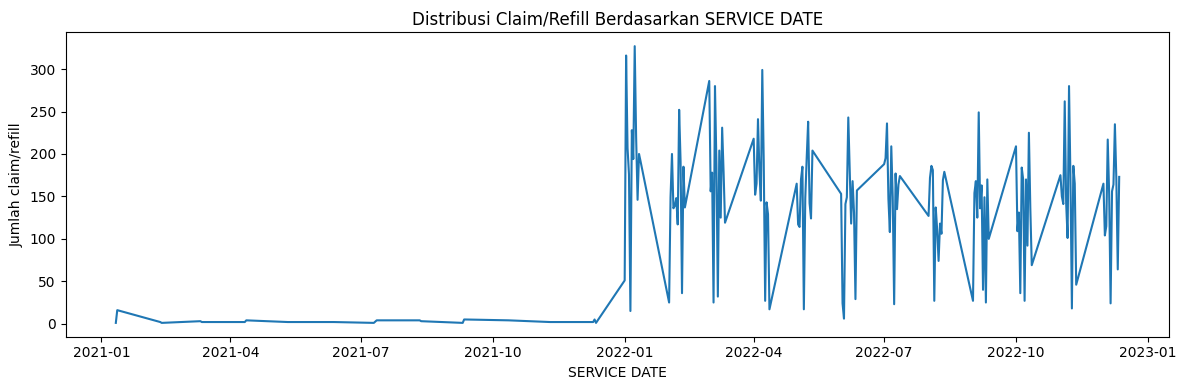

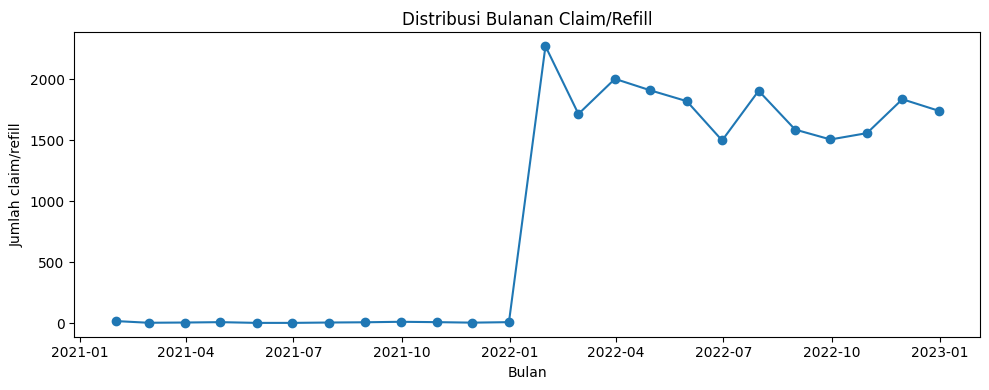

In [11]:
print("Tanggal SERVICE DATE minimum:", df["SERVICE DATE"].min())
print("Tanggal SERVICE DATE maksimum:", df["SERVICE DATE"].max())

daily_refill = (
    df.dropna(subset=["SERVICE DATE"])
      .groupby("SERVICE DATE")
      .size()
      .rename("n_refill")
      .reset_index()
)

display(daily_refill.head())

plt.figure(figsize=(12, 4))
plt.plot(daily_refill["SERVICE DATE"], daily_refill["n_refill"])
plt.xlabel("SERVICE DATE")
plt.ylabel("Jumlah claim/refill")
plt.title("Distribusi Claim/Refill Berdasarkan SERVICE DATE")
plt.tight_layout()
plt.show()

monthly_refill = (
    df.dropna(subset=["SERVICE DATE"])
      .set_index("SERVICE DATE")
      .resample("ME")
      .size()
      .rename("n_refill")
      .reset_index()
)

plt.figure(figsize=(10, 4))
plt.plot(monthly_refill["SERVICE DATE"], monthly_refill["n_refill"], marker="o")
plt.xlabel("Bulan")
plt.ylabel("Jumlah claim/refill")
plt.title("Distribusi Bulanan Claim/Refill")
plt.tight_layout()
plt.show()

## 9. Cek Imbalance Label
Bagian ini membuat label klasifikasi dan melihat distribusi kelas.

Label default:
- `target = 1`: non-adherent
- `target = 0`: adherent

Pada mode `standard`, pasien dianggap non-adherent jika `ADHERENCE < 9`.

,count,percent
0_adherent_or_other,2127,43.810505
1_non_adherent,2728,56.189495


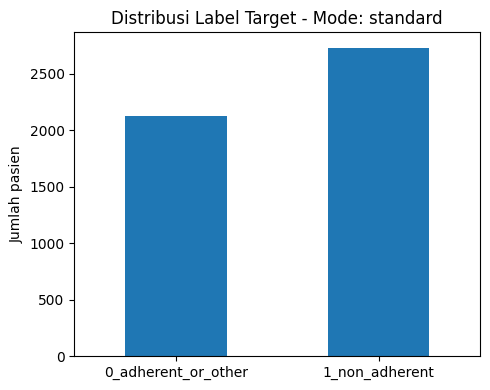

Imbalance ratio mayoritas:minotitas = 1.28:1


In [12]:
def create_target_from_adherence(adherence, label_mode="standard", severe_threshold=3):
    if label_mode == "standard":
        return (adherence < 9).astype(int)
    elif label_mode == "severe":
        return (adherence <= severe_threshold).astype(int)
    else:
        raise ValueError("label_mode harus 'standard' atau 'severe'.")

patient_adherence["target"] = create_target_from_adherence(
    patient_adherence["ADHERENCE"],
    label_mode=LABEL_MODE,
    severe_threshold=SEVERE_THRESHOLD
)

label_dist = patient_adherence["target"].value_counts().sort_index()
label_pct = patient_adherence["target"].value_counts(normalize=True).sort_index() * 100

label_summary = pd.DataFrame({
    "count": label_dist,
    "percent": label_pct
})
label_summary.index = ["0_adherent_or_other", "1_non_adherent"]
display(label_summary)

plt.figure(figsize=(5, 4))
label_summary["count"].plot(kind="bar")
plt.xticks(rotation=0)
plt.ylabel("Jumlah pasien")
plt.title(f"Distribusi Label Target - Mode: {LABEL_MODE}")
plt.tight_layout()
plt.show()

imbalance_ratio = label_summary["count"].max() / label_summary["count"].min()
print(f"Imbalance ratio mayoritas:minotitas = {imbalance_ratio:.2f}:1")

# Notebook 2: Modeling Pipeline
Bagian ini mengubah data mentah menjadi input sekuensial untuk LSTM/BiLSTM.

## 10. Cleaning untuk Modeling
Pada tahap modeling:
- pastikan tanggal valid
- hapus data tanpa `patient_id`, `SERVICE DATE`, atau `ADHERENCE`
- buat target patient-level
- hindari data leakage dengan tidak memakai `ADHERENCE` sebagai fitur

In [13]:
def prepare_modeling_base(df, label_mode="standard", severe_threshold=3):
    df = basic_cleaning(df)

    required_cols = ["patient_id", "SERVICE DATE", "ADHERENCE"]
    for col in required_cols:
        if col not in df.columns:
            raise ValueError(f"Kolom wajib tidak ditemukan: {col}")

    df = df.dropna(subset=["patient_id", "SERVICE DATE", "ADHERENCE"]).copy()

    # Label dibuat di level pasien.
    patient_label = (
        df.groupby("patient_id", as_index=False)
          .agg(
              ADHERENCE=("ADHERENCE", "max"),
              disease_type=("disease_type", lambda x: x.mode().iloc[0] if len(x.mode()) else x.iloc[0])
          )
    )

    patient_label["target"] = create_target_from_adherence(
        patient_label["ADHERENCE"],
        label_mode=label_mode,
        severe_threshold=severe_threshold
    )

    return df, patient_label

df_model, patient_label = prepare_modeling_base(
    df_raw,
    label_mode=LABEL_MODE,
    severe_threshold=SEVERE_THRESHOLD
)

print("df_model shape:", df_model.shape)
print("patient_label shape:", patient_label.shape)
display(patient_label.head())
display(patient_label["target"].value_counts().sort_index().rename("count").to_frame())

df_model shape: (21429, 43)
patient_label shape: (3851, 4)


,patient_id,ADHERENCE,disease_type,target
0,92222888_1_XRS TZRISZYI GQTRUDQ NYZXBIYZ,5,diabetes,1
1,92222969_1_XS ZNNZH XUGWZXBI,8,diabetes,1
2,92223895_1_XS KZLZVZTIBQN PZRXZR,12,diabetes,0
3,92224675_0_XS RUXBIDZZI XZSHIRI,9,diabetes,0
4,92225985_0_XR BODYXZN XZJZCHZNI,8,diabetes,1


,count
target,
0,1900
1,1951


## 11. Agregasi Patient-Date
Karena satu pasien bisa memiliki beberapa claim/obat pada tanggal yang sama, data perlu diagregasi menjadi satu baris per `patient_id + SERVICE DATE`.

Fitur numerik yang digunakan disesuaikan dengan kolom yang tersedia di dataset.

In [14]:
def find_existing_columns(df, candidates):
    return [c for c in candidates if c in df.columns]

NUMERIC_SUM_CANDIDATES = [
    "UNITS",
    "AMOUNT CLAIMED",
    "TOTAL AMOUNT PAID",
    "CO-PAY",
    "NET AMOUNT",
    "CLAIM AMOUNT",
]

NUMERIC_MEAN_CANDIDATES = [
    "CURRENT AGE",
    "AGE",
]

COUNT_UNIQUE_CANDIDATES = [
    "CLM CODE",
    "CODE DESCRIPTION",
    "PROVIDER",
    "PRACTICE NUMBER",
    "NPI",
    "DISCIPLINE",
]

CATEGORICAL_CANDIDATES = [
    "GENDER",
    "PAYER NAME",
    "OPTION NAME",
    "disease_type",
]

sum_cols = find_existing_columns(df_model, NUMERIC_SUM_CANDIDATES)
mean_cols = find_existing_columns(df_model, NUMERIC_MEAN_CANDIDATES)
unique_cols = find_existing_columns(df_model, COUNT_UNIQUE_CANDIDATES)
cat_cols = find_existing_columns(df_model, CATEGORICAL_CANDIDATES)

print("Kolom sum:", sum_cols)
print("Kolom mean:", mean_cols)
print("Kolom unique count:", unique_cols)
print("Kolom kategori:", cat_cols)

# Pastikan kolom numerik benar-benar numerik.
for col in sum_cols + mean_cols:
    df_model[col] = pd.to_numeric(df_model[col], errors="coerce").fillna(0)

def aggregate_patient_date(df):
    agg_dict = {}

    for col in sum_cols:
        agg_dict[f"sum_{col}"] = (col, "sum")
        agg_dict[f"mean_{col}"] = (col, "mean")

    for col in mean_cols:
        agg_dict[f"mean_{col}"] = (col, "mean")

    for col in unique_cols:
        agg_dict[f"nunique_{col}"] = (col, "nunique")

    # jumlah baris claim pada tanggal tersebut
    agg_dict["n_claims_on_date"] = ("patient_id", "size")

    patient_date = (
        df.groupby(["patient_id", "SERVICE DATE"])
          .agg(**agg_dict)
          .reset_index()
          .sort_values(["patient_id", "SERVICE DATE"])
    )

    # Tambahkan fitur statis/kategori per pasien, lalu akan di-encode.
    static_parts = []
    for col in cat_cols:
        tmp = (
            df.groupby("patient_id", as_index=False)
              .agg(**{col: (col, lambda x: x.mode().iloc[0] if len(x.mode()) else x.iloc[0])})
        )
        static_parts.append(tmp)

    if static_parts:
        static_df = static_parts[0]
        for tmp in static_parts[1:]:
            static_df = static_df.merge(tmp, on="patient_id", how="left")
        patient_date = patient_date.merge(static_df, on="patient_id", how="left")

    return patient_date

patient_date = aggregate_patient_date(df_model)

# Fitur temporal
patient_date["event_index"] = patient_date.groupby("patient_id").cumcount() + 1
patient_date["gap_days"] = (
    patient_date.groupby("patient_id")["SERVICE DATE"]
    .diff()
    .dt.days
    .fillna(0)
)
patient_date["days_since_first"] = (
    patient_date["SERVICE DATE"] - patient_date.groupby("patient_id")["SERVICE DATE"].transform("min")
).dt.days

print("patient_date shape:", patient_date.shape)
display(patient_date.head())

Kolom sum: ['UNITS', 'AMOUNT CLAIMED', 'TOTAL AMOUNT PAID', 'CO-PAY']
Kolom mean: ['CURRENT AGE']
Kolom unique count: ['CLM CODE', 'CODE DESCRIPTION', 'PROVIDER']
Kolom kategori: ['GENDER', 'PAYER NAME', 'OPTION NAME', 'disease_type']
patient_date shape: (15034, 22)


,patient_id,SERVICE DATE,sum_UNITS,mean_UNITS,sum_AMOUNT CLAIMED,mean_AMOUNT CLAIMED,sum_TOTAL AMOUNT PAID,mean_TOTAL AMOUNT PAID,sum_CO-PAY,mean_CO-PAY,mean_CURRENT AGE,nunique_CLM CODE,nunique_CODE DESCRIPTION,nunique_PROVIDER,n_claims_on_date,GENDER,PAYER NAME,OPTION NAME,disease_type,event_index,gap_days,days_since_first
0,92222888_1_XRS TZRISZYI GQTRUDQ NYZXBIYZ,2022-06-02,60,60.0,1067.19,1067.19,1067.19,1067.19,0,0.0,60.0,1,1,1,1,M,APPLIED DIESEL AND POWER PVT LTD,PRIVATE HOSPITAL PLUS,diabetes,1,0.0,0
1,92222888_1_XRS TZRISZYI GQTRUDQ NYZXBIYZ,2022-09-01,60,60.0,1067.18,1067.18,1067.18,1067.18,0,0.0,60.0,1,1,1,1,M,APPLIED DIESEL AND POWER PVT LTD,PRIVATE HOSPITAL PLUS,diabetes,2,91.0,91
2,92222888_1_XRS TZRISZYI GQTRUDQ NYZXBIYZ,2022-09-07,60,60.0,3280.34,3280.34,3280.34,3280.34,0,0.0,60.0,1,1,1,1,M,APPLIED DIESEL AND POWER PVT LTD,PRIVATE HOSPITAL PLUS,diabetes,3,6.0,97
3,92222969_1_XS ZNNZH XUGWZXBI,2022-01-08,120,60.0,40904.96,20452.48,40904.96,20452.48,0,0.0,63.0,2,2,1,2,F,INNSCOR (PVT) LTD,PRIVATE HOSPITAL PLUS,diabetes,1,0.0,0
4,92222969_1_XS ZNNZH XUGWZXBI,2022-03-05,120,60.0,16882.86,8441.43,16882.86,8441.43,0,0.0,63.0,2,2,1,2,F,INNSCOR (PVT) LTD,PRIVATE HOSPITAL PLUS,diabetes,2,56.0,56


## 12. Encoding Fitur dan Standardisasi
Fitur kategori diubah menjadi one-hot encoding. Fitur numerik akan di-standardisasi berdasarkan data train saja nanti agar tidak terjadi data leakage.

In [15]:
def encode_patient_date_features(patient_date):
    data = patient_date.copy()

    # One-hot encoding untuk fitur kategori yang tersedia.
    categorical_available = [c for c in cat_cols if c in data.columns]
    if categorical_available:
        data = pd.get_dummies(data, columns=categorical_available, dummy_na=True)

    # Fitur yang tidak digunakan langsung oleh model
    exclude_cols = ["patient_id", "SERVICE DATE"]
    feature_cols = [c for c in data.columns if c not in exclude_cols]

    # Pastikan semua fitur numerik
    for c in feature_cols:
        data[c] = pd.to_numeric(data[c], errors="coerce").fillna(0)

    return data, feature_cols

patient_date_encoded, feature_cols = encode_patient_date_features(patient_date)

print("Jumlah fitur per timestep:", len(feature_cols))
print(feature_cols[:30])
display(patient_date_encoded.head())

Jumlah fitur per timestep: 1028
['sum_UNITS', 'mean_UNITS', 'sum_AMOUNT CLAIMED', 'mean_AMOUNT CLAIMED', 'sum_TOTAL AMOUNT PAID', 'mean_TOTAL AMOUNT PAID', 'sum_CO-PAY', 'mean_CO-PAY', 'mean_CURRENT AGE', 'nunique_CLM CODE', 'nunique_CODE DESCRIPTION', 'nunique_PROVIDER', 'n_claims_on_date', 'event_index', 'gap_days', 'days_since_first', 'GENDER_F', 'GENDER_M', 'GENDER_nan', 'PAYER NAME_24 HOUR MEDICAL CENTRE', 'PAYER NAME_A A OMAR+CO', 'PAYER NAME_A I DAVIS CO (PVT) LTD', 'PAYER NAME_A J PAARDENKOOPER', 'PAYER NAME_A LUCKY BRAND PVT LTD', 'PAYER NAME_A M BUS & TRUCK SPARES', 'PAYER NAME_A SQUARED DISTRIBUTORS PVT LTD', 'PAYER NAME_AAYU PACKAGING PVT LTD', 'PAYER NAME_ABENSBERG INVESTMENTS TA HIPPO POOLS WILDERNESS CAMP', 'PAYER NAME_ACCOUNTING + EXECUTOR SERVICES (PVT) LTD', 'PAYER NAME_AFC COMMERICAL BANK']


,patient_id,SERVICE DATE,sum_UNITS,mean_UNITS,sum_AMOUNT CLAIMED,mean_AMOUNT CLAIMED,sum_TOTAL AMOUNT PAID,mean_TOTAL AMOUNT PAID,sum_CO-PAY,mean_CO-PAY,mean_CURRENT AGE,nunique_CLM CODE,nunique_CODE DESCRIPTION,nunique_PROVIDER,n_claims_on_date,event_index,gap_days,days_since_first,GENDER_F,GENDER_M,GENDER_nan,PAYER NAME_24 HOUR MEDICAL CENTRE,PAYER NAME_A A OMAR+CO,PAYER NAME_A I DAVIS CO (PVT) LTD,PAYER NAME_A J PAARDENKOOPER,PAYER NAME_A LUCKY BRAND PVT LTD,PAYER NAME_A M BUS & TRUCK SPARES,PAYER NAME_A SQUARED DISTRIBUTORS PVT LTD,PAYER NAME_AAYU PACKAGING PVT LTD,PAYER NAME_ABENSBERG INVESTMENTS TA HIPPO POOLS WILDERNESS CAMP,PAYER NAME_ACCOUNTING + EXECUTOR SERVICES (PVT) LTD,PAYER NAME_AFC COMMERICAL BANK,PAYER NAME_AFRICA STEEL P/L,PAYER NAME_AFRICA UNI,PAYER NAME_AFRICA UNIVERSITY STUDENTS,PAYER NAME_AFRICAN BANKING CORPORATION,PAYER NAME_AFRICAN CENTURY LEASING LIMITED,PAYER NAME_AFRICAN DISTILLERS GENERAL ACC,PAYER NAME_AFRICAN DISTILLERS LTD,PAYER NAME_AFRITRACTORS ZIMBABWE,PAYER NAME_AFROSOFT P/L,PAYER NAME_AGRICULTURAL RESEARCH CLOSED,PAYER NAME_AGRILINK ACCOUNTING SERVICES,PAYER NAME_AGROWTH FARMING (PRIVATE) LIMITED,PAYER NAME_AIR ZIMBABWE PVT LTD,PAYER NAME_AIRPORTS COMPANY OF ZIMBABWE (NOW ON SECURE),PAYER NAME_ALLIED TIMBERS ZIMBABWE,PAYER NAME_ALLITACK TRADING PVT LIMITED,PAYER NAME_ALMIN METAL INDUSTRIES LIMITED,PAYER NAME_ALPHA PACKAGING PVT LTD,...,PAYER NAME_ZAMBEZI RIVER AUTHORITY PENSIONERS,PAYER NAME_ZAOGA GRANGE TA THE GRANGE CHRIST SCHL,PAYER NAME_ZB FINANCIAL HOLDINGS,PAYER NAME_ZBC DOMESTIC ACCOUNT ZIMBABWE BROADCASTING CORPORATION,PAYER NAME_ZIBAWU (ZIMBABWE BANKS & ALLIED WORKERS UNION,PAYER NAME_ZIMASCO HEAD OFFICE HARARE,PAYER NAME_ZIMASCO KWEKWE DIVISION,PAYER NAME_ZIMASCO SHURUGWI DIVISION,PAYER NAME_ZIMBABWE BROADCASTING CORPORATION ZBC,PAYER NAME_ZIMBABWE CONSOLIDATED DIAMOND COMPANY,PAYER NAME_ZIMBABWE CONSTRUCTION AND ALLIED TRADES WORKERS UNION (NEW ACC),PAYER NAME_ZIMBABWE COUNCIL FOR HIGHER EDUCATION ZIMCHE,PAYER NAME_ZIMBABWE ELECTRICITY INDUSTRY PENSION FUND,PAYER NAME_ZIMBABWE ENERGY REGULATORY AUTHORITY,PAYER NAME_ZIMBABWE INTERNATIONAL QUARRIES P/L,PAYER NAME_ZIMBABWE INVESTMENT DEVELOPMENT AGENCY,PAYER NAME_ZIMBABWE MOTOR TRIMMERS,PAYER NAME_ZIMBABWE NATIONAL ROAD ADMINISTRATION,PAYER NAME_ZIMBABWE OPEN UNIVERSITY,PAYER NAME_ZIMBABWE SPINNERS & WEAVERS LTD,PAYER NAME_ZIMBABWE SUGAR SALES (PVT) LTD,PAYER NAME_ZIMBABWE TEACHERS'ASSOCIATION,PAYER NAME_ZIMBABWE TOBACCO ASSOCIATION,PAYER NAME_ZIMBABWE TRADE EXCHANGE,PAYER NAME_ZIMFLEX T/A ZIMBABWE FLOWER EXPORTERS PL,PAYER NAME_ZIMFLORA PRIVATE LIMITED,PAYER NAME_ZIMGOLD INDUSTRIES (PVT) LTD,PAYER NAME_ZIMIND (PVT) LTD ATTL TSWATSWA,PAYER NAME_ZIMLEAF HOLDINGS LTD,PAYER NAME_ZIMPAPERS (1980) LTD TA NATPRINT,PAYER NAME_ZIMSWITCH,PAYER NAME_ZIMZAC PL TA SVEND SORENSEN,PAYER NAME_ZISCO STEEL,PAYER NAME_ZM CHIRENJE SURGERY,PAYER NAME_ZUVA PETROLEUM FORMERYLY BP&SHELL(PENSIONE,PAYER NAME_ZVENYIKA Z MR,PAYER NAME_ZVISHAVANE TOWN COUNCIL,PAYER NAME_nan,OPTION NAME_BASICARE,OPTION NAME_ICARE,OPTION NAME_MEDEXEC,OPTION NAME_MEDEXEC PLUS,OPTION NAME_PRIME,OPTION NAME_PRIVATE HOSPITAL,OPTION NAME_PRIVATE HOSPITAL PLUS,OPTION NAME_PRIVATE LITE,OPTION NAME_STUDYMATE PRIVATE,OPTION NAME_nan,disease_type_diabetes,disease_type_nan
0,92222888_1_XRS TZRISZYI GQTRUDQ NYZXBIYZ,2022-06-02,60,60.0,1067.19,1067.19,1067.19,1067.19,0,0.0,60.0,1,1,1,1,1,0.0,0,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,True,False
1,92222888_1_XRS TZRISZYI GQTRUDQ NYZXBIYZ,2022-09-01,60,60.0,1067.18,1067.18,1067.18,1067.18,0,0.0,60.0,1,1,1,1,2,9

## 13. Pembentukan Sequence untuk LSTM/BiLSTM
Data dibentuk menjadi tensor 3D:

```text
X = [jumlah_pasien, panjang_sequence, jumlah_fitur]
y = [jumlah_pasien]
```

Jika jumlah event pasien kurang dari `MAX_SEQ_LEN`, maka dilakukan padding dengan nilai 0.

In [16]:
def build_sequences(patient_date_encoded, patient_label, feature_cols, max_seq_len=6, sequence_mode="first"):
    X_list = []
    y_list = []
    patient_ids = []

    label_map = patient_label.set_index("patient_id")["target"].to_dict()

    grouped = patient_date_encoded.sort_values(["patient_id", "SERVICE DATE"]).groupby("patient_id")

    for pid, g in grouped:
        if pid not in label_map:
            continue

        g = g.sort_values("SERVICE DATE")

        if sequence_mode == "first":
            g = g.head(max_seq_len)
        elif sequence_mode == "last":
            g = g.tail(max_seq_len)
        else:
            raise ValueError("sequence_mode harus 'first' atau 'last'.")

        arr = g[feature_cols].values.astype(np.float32)

        # Padding
        if arr.shape[0] < max_seq_len:
            pad_len = max_seq_len - arr.shape[0]
            pad = np.zeros((pad_len, len(feature_cols)), dtype=np.float32)
            if sequence_mode == "first":
                arr = np.vstack([arr, pad])
            else:
                arr = np.vstack([pad, arr])

        X_list.append(arr)
        y_list.append(label_map[pid])
        patient_ids.append(pid)

    X = np.stack(X_list)
    y = np.array(y_list).astype(int)
    patient_ids = np.array(patient_ids)

    return X, y, patient_ids

X, y, sequence_patient_ids = build_sequences(
    patient_date_encoded,
    patient_label,
    feature_cols,
    max_seq_len=MAX_SEQ_LEN,
    sequence_mode=SEQUENCE_MODE
)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Distribusi y:", pd.Series(y).value_counts().sort_index().to_dict())

X shape: (3851, 6, 1028)
y shape: (3851,)
Distribusi y: {0: 1900, 1: 1951}


## 14. Train/Validation/Test Split
Split dilakukan pada level pasien. Ini penting agar data pasien yang sama tidak muncul di train dan test.

In [17]:
X_train, X_temp, y_train, y_temp, pid_train, pid_temp = train_test_split(
    X, y, sequence_patient_ids,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

X_val, X_test, y_val, y_test, pid_val, pid_test = train_test_split(
    X_temp, y_temp, pid_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

print("Train:", X_train.shape, pd.Series(y_train).value_counts(normalize=True).sort_index().to_dict())
print("Val  :", X_val.shape, pd.Series(y_val).value_counts(normalize=True).sort_index().to_dict())
print("Test :", X_test.shape, pd.Series(y_test).value_counts(normalize=True).sort_index().to_dict())

Train: (2695, 6, 1028) {0: 0.4935064935064935, 1: 0.5064935064935064}
Val  : (578, 6, 1028) {0: 0.4930795847750865, 1: 0.5069204152249135}
Test : (578, 6, 1028) {0: 0.4930795847750865, 1: 0.5069204152249135}


## 15. Standardisasi Fitur
Scaler di-fit hanya pada data train, lalu diterapkan ke train, validation, dan test.

In [18]:
def scale_3d_train_val_test(X_train, X_val, X_test):
    n_train, t, f = X_train.shape

    scaler = StandardScaler()
    X_train_2d = X_train.reshape(-1, f)
    scaler.fit(X_train_2d)

    def transform(X):
        n, t, f = X.shape
        X_2d = X.reshape(-1, f)
        X_scaled = scaler.transform(X_2d)
        return X_scaled.reshape(n, t, f).astype(np.float32)

    return transform(X_train), transform(X_val), transform(X_test), scaler

X_train_scaled, X_val_scaled, X_test_scaled, scaler = scale_3d_train_val_test(X_train, X_val, X_test)

print("Scaled shapes:", X_train_scaled.shape, X_val_scaled.shape, X_test_scaled.shape)

Scaled shapes: (2695, 6, 1028) (578, 6, 1028) (578, 6, 1028)


## 16. Fungsi Evaluasi Model
Fungsi ini digunakan untuk mengevaluasi baseline, LSTM, dan BiLSTM secara konsisten.

In [19]:
def compute_metrics(y_true, y_prob, threshold=0.5, label="model"):
    y_pred = (y_prob >= threshold).astype(int)

    cm = confusion_matrix(y_true, y_pred)
    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
        specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan
    else:
        specificity = np.nan

    metrics = {
        "model": label,
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "specificity": specificity,
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else np.nan,
        "pr_auc": average_precision_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else np.nan,
    }
    return metrics, cm, y_pred

def print_evaluation(y_true, y_prob, threshold=0.5, label="model"):
    metrics, cm, y_pred = compute_metrics(y_true, y_prob, threshold=threshold, label=label)
    print(pd.Series(metrics))
    print("\nConfusion Matrix:")
    print(cm)
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, zero_division=0))
    return metrics, cm, y_pred

def find_best_threshold(y_true, y_prob, metric="f1"):
    thresholds = np.linspace(0.05, 0.95, 91)
    scores = []
    for th in thresholds:
        y_pred = (y_prob >= th).astype(int)
        if metric == "f1":
            score = f1_score(y_true, y_pred, zero_division=0)
        elif metric == "recall":
            score = recall_score(y_true, y_pred, zero_division=0)
        else:
            raise ValueError("metric hanya mendukung 'f1' atau 'recall'")
        scores.append(score)

    best_idx = int(np.argmax(scores))
    return thresholds[best_idx], scores[best_idx]

def plot_roc_pr_curves(y_true, y_prob, title="Model"):
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    precision, recall, _ = precision_recall_curve(y_true, y_prob)

    plt.figure(figsize=(5, 4))
    plt.plot(fpr, tpr)
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve - {title}")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(5, 4))
    plt.plot(recall, precision)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"Precision-Recall Curve - {title}")
    plt.tight_layout()
    plt.show()

## 17. Baseline Model: Random Forest
Baseline digunakan untuk mengetahui apakah LSTM/BiLSTM memang memberikan nilai tambah dibanding model non-sekuensial.

Karena Random Forest tidak menerima input 3D, sequence diratakan menjadi 2D.

Best threshold RF berdasarkan validation F1: 0.49999999999999994 F1: 0.7516556291390728
model          Random Forest Baseline
threshold                         0.5
accuracy                     0.681661
precision                    0.683502
recall                       0.692833
specificity                  0.670175
f1                           0.688136
roc_auc                      0.735249
pr_auc                       0.724597
dtype: object

Confusion Matrix:
[[191  94]
 [ 90 203]]

Classification Report:
              precision    recall  f1-score   support

           0       0.68      0.67      0.67       285
           1       0.68      0.69      0.69       293

    accuracy                           0.68       578
   macro avg       0.68      0.68      0.68       578
weighted avg       0.68      0.68      0.68       578



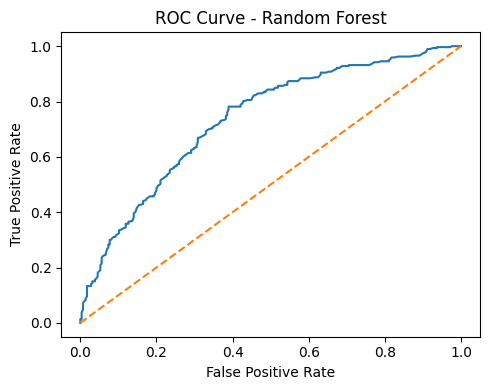

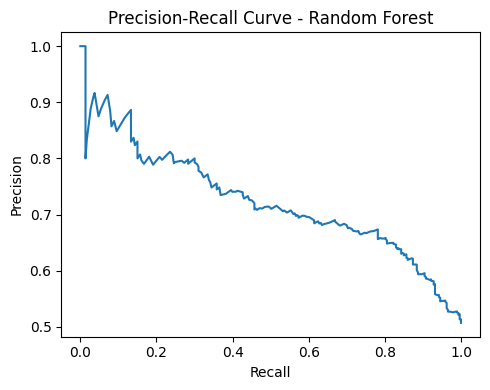

In [20]:
X_train_flat = X_train_scaled.reshape(X_train_scaled.shape[0], -1)
X_val_flat = X_val_scaled.reshape(X_val_scaled.shape[0], -1)
X_test_flat = X_test_scaled.reshape(X_test_scaled.shape[0], -1)

rf = RandomForestClassifier(
    n_estimators=300,
    random_state=RANDOM_STATE,
    class_weight="balanced" if USE_CLASS_WEIGHT else None,
    n_jobs=-1
)

rf.fit(X_train_flat, y_train)

rf_val_prob = rf.predict_proba(X_val_flat)[:, 1]
rf_test_prob = rf.predict_proba(X_test_flat)[:, 1]

rf_best_th, rf_best_score = find_best_threshold(y_val, rf_val_prob, metric="f1")
print("Best threshold RF berdasarkan validation F1:", rf_best_th, "F1:", rf_best_score)

rf_metrics, rf_cm, rf_pred = print_evaluation(
    y_test,
    rf_test_prob,
    threshold=rf_best_th,
    label="Random Forest Baseline"
)

plot_roc_pr_curves(y_test, rf_test_prob, title="Random Forest")

## 18. Dataset dan DataLoader PyTorch
Bagian ini menyiapkan dataset untuk LSTM dan BiLSTM.

In [21]:
if not TORCH_AVAILABLE:
    raise ImportError("PyTorch belum tersedia. Install PyTorch terlebih dahulu untuk menjalankan LSTM/BiLSTM.")

class SequenceDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = SequenceDataset(X_train_scaled, y_train)
val_dataset = SequenceDataset(X_val_scaled, y_val)
test_dataset = SequenceDataset(X_test_scaled, y_test)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cpu')

## 19. Definisi Model LSTM dan BiLSTM
Model menggunakan output hidden state terakhir untuk klasifikasi biner.

In [22]:
class LSTMClassifier(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=1, dropout=0.2, bidirectional=False):
        super().__init__()
        self.bidirectional = bidirectional

        lstm_dropout = dropout if num_layers > 1 else 0

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=lstm_dropout,
            bidirectional=bidirectional
        )

        direction_factor = 2 if bidirectional else 1
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size * direction_factor, 1)

    def forward(self, x):
        out, (h_n, c_n) = self.lstm(x)

        if self.bidirectional:
            # Ambil hidden state terakhir dari forward dan backward direction.
            h_forward = h_n[-2]
            h_backward = h_n[-1]
            h = torch.cat([h_forward, h_backward], dim=1)
        else:
            h = h_n[-1]

        h = self.dropout(h)
        logits = self.fc(h).squeeze(1)
        return logits

class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, logits, targets):
        bce = nn.functional.binary_cross_entropy_with_logits(
            logits,
            targets,
            reduction="none"
        )
        probs = torch.sigmoid(logits)
        pt = torch.where(targets == 1, probs, 1 - probs)
        focal_weight = (1 - pt) ** self.gamma

        if self.alpha is not None:
            alpha_t = torch.where(targets == 1, self.alpha, 1 - self.alpha)
            focal_weight = alpha_t * focal_weight

        loss = focal_weight * bce
        return loss.mean()

## 20. Training Function
Training menggunakan validation loss untuk menyimpan model terbaik.

In [23]:
def get_class_pos_weight(y_train):
    n_pos = np.sum(y_train == 1)
    n_neg = np.sum(y_train == 0)
    if n_pos == 0:
        return torch.tensor(1.0, dtype=torch.float32)
    return torch.tensor(n_neg / n_pos, dtype=torch.float32)

def train_torch_model(model, train_loader, val_loader, y_train, epochs=20, lr=1e-3,
                      use_class_weight=True, use_focal_loss=False, focal_gamma=2.0):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    pos_weight = get_class_pos_weight(y_train).to(device) if use_class_weight else None

    if use_focal_loss:
        # alpha positif dihitung dari proporsi kelas negatif
        alpha = None
        if use_class_weight:
            alpha_value = np.mean(y_train == 0)
            alpha = torch.tensor(alpha_value, dtype=torch.float32).to(device)
        criterion = FocalLoss(alpha=alpha, gamma=focal_gamma)
    else:
        criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    best_val_loss = np.inf
    best_state = None
    history = []

    for epoch in range(1, epochs + 1):
        model.train()
        train_losses = []

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            train_losses.append(loss.item())

        model.eval()
        val_losses = []
        val_probs = []
        val_true = []

        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(device)
                yb = yb.to(device)
                logits = model(xb)
                loss = criterion(logits, yb)
                probs = torch.sigmoid(logits)

                val_losses.append(loss.item())
                val_probs.extend(probs.cpu().numpy())
                val_true.extend(yb.cpu().numpy())

        train_loss = float(np.mean(train_losses))
        val_loss = float(np.mean(val_losses))
        val_probs = np.array(val_probs)
        val_true = np.array(val_true).astype(int)
        val_f1 = f1_score(val_true, val_probs >= 0.5, zero_division=0)
        val_auc = roc_auc_score(val_true, val_probs) if len(np.unique(val_true)) == 2 else np.nan

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "val_f1": val_f1,
            "val_auc": val_auc
        })

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

        print(f"Epoch {epoch:02d}/{epochs} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | val_f1={val_f1:.4f} | val_auc={val_auc:.4f}")

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, pd.DataFrame(history)

def predict_torch_model(model, loader):
    model.eval()
    probs = []
    y_true = []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            logits = model(xb)
            prob = torch.sigmoid(logits)
            probs.extend(prob.cpu().numpy())
            y_true.extend(yb.numpy())

    return np.array(y_true).astype(int), np.array(probs)

def plot_training_history(history, title):
    plt.figure(figsize=(7, 4))
    plt.plot(history["epoch"], history["train_loss"], label="train_loss")
    plt.plot(history["epoch"], history["val_loss"], label="val_loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()

## 21. Model LSTM
Eksperimen pertama menggunakan LSTM satu arah.

Epoch 01/20 | train_loss=0.6239 | val_loss=0.5759 | val_f1=0.7378 | val_auc=0.7664
Epoch 02/20 | train_loss=0.5578 | val_loss=0.5713 | val_f1=0.7307 | val_auc=0.7704
Epoch 03/20 | train_loss=0.5056 | val_loss=0.5741 | val_f1=0.7234 | val_auc=0.7726
Epoch 04/20 | train_loss=0.4568 | val_loss=0.6008 | val_f1=0.6762 | val_auc=0.7556
Epoch 05/20 | train_loss=0.3971 | val_loss=0.6430 | val_f1=0.6359 | val_auc=0.7447
Epoch 06/20 | train_loss=0.3680 | val_loss=0.6373 | val_f1=0.6997 | val_auc=0.7555
Epoch 07/20 | train_loss=0.3281 | val_loss=0.6610 | val_f1=0.6964 | val_auc=0.7537
Epoch 08/20 | train_loss=0.3070 | val_loss=0.6632 | val_f1=0.7252 | val_auc=0.7617
Epoch 09/20 | train_loss=0.2885 | val_loss=0.7547 | val_f1=0.6328 | val_auc=0.7328
Epoch 10/20 | train_loss=0.2721 | val_loss=0.8432 | val_f1=0.5451 | val_auc=0.7145
Epoch 11/20 | train_loss=0.2774 | val_loss=0.7296 | val_f1=0.6813 | val_auc=0.7398
Epoch 12/20 | train_loss=0.2549 | val_loss=0.7696 | val_f1=0.7115 | val_auc=0.7457
Epoc

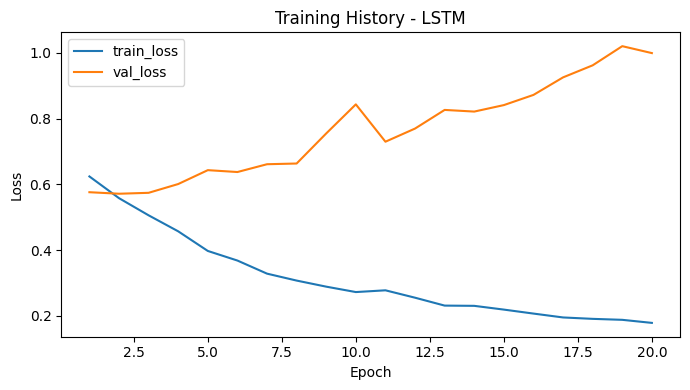

Best threshold LSTM berdasarkan validation F1: 0.42999999999999994 F1: 0.7354260089686099
model              LSTM
threshold          0.43
accuracy        0.66263
precision       0.62963
recall         0.812287
specificity    0.508772
f1             0.709389
roc_auc        0.738375
pr_auc         0.736551
dtype: object

Confusion Matrix:
[[145 140]
 [ 55 238]]

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.51      0.60       285
           1       0.63      0.81      0.71       293

    accuracy                           0.66       578
   macro avg       0.68      0.66      0.65       578
weighted avg       0.68      0.66      0.65       578



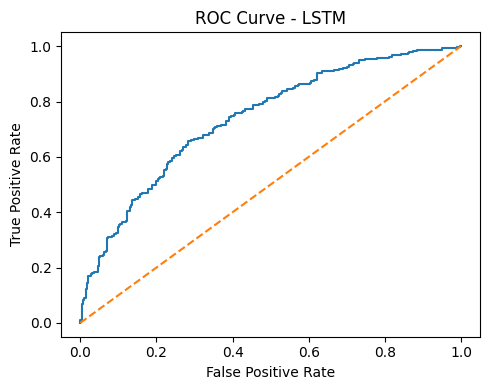

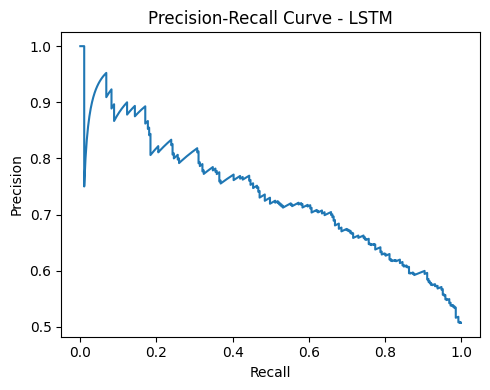

In [24]:
input_size = X_train_scaled.shape[2]

lstm_model = LSTMClassifier(
    input_size=input_size,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT,
    bidirectional=False
)

lstm_model, lstm_history = train_torch_model(
    lstm_model,
    train_loader,
    val_loader,
    y_train,
    epochs=EPOCHS,
    lr=LEARNING_RATE,
    use_class_weight=USE_CLASS_WEIGHT,
    use_focal_loss=USE_FOCAL_LOSS,
    focal_gamma=FOCAL_GAMMA
)

plot_training_history(lstm_history, "Training History - LSTM")

y_val_lstm, lstm_val_prob = predict_torch_model(lstm_model, val_loader)
y_test_lstm, lstm_test_prob = predict_torch_model(lstm_model, test_loader)

lstm_best_th, lstm_best_score = find_best_threshold(y_val_lstm, lstm_val_prob, metric="f1")
print("Best threshold LSTM berdasarkan validation F1:", lstm_best_th, "F1:", lstm_best_score)

lstm_metrics, lstm_cm, lstm_pred = print_evaluation(
    y_test,
    lstm_test_prob,
    threshold=lstm_best_th,
    label="LSTM"
)

plot_roc_pr_curves(y_test, lstm_test_prob, title="LSTM")

## 22. Model BiLSTM
Eksperimen kedua menggunakan Bidirectional LSTM.

Epoch 01/20 | train_loss=0.6147 | val_loss=0.5861 | val_f1=0.7322 | val_auc=0.7629
Epoch 02/20 | train_loss=0.5403 | val_loss=0.5916 | val_f1=0.6962 | val_auc=0.7582
Epoch 03/20 | train_loss=0.4832 | val_loss=0.6171 | val_f1=0.6092 | val_auc=0.7446
Epoch 04/20 | train_loss=0.4231 | val_loss=0.5879 | val_f1=0.7061 | val_auc=0.7607
Epoch 05/20 | train_loss=0.3718 | val_loss=0.6304 | val_f1=0.6806 | val_auc=0.7519
Epoch 06/20 | train_loss=0.3276 | val_loss=0.6591 | val_f1=0.7069 | val_auc=0.7550
Epoch 07/20 | train_loss=0.2978 | val_loss=0.7059 | val_f1=0.6773 | val_auc=0.7456
Epoch 08/20 | train_loss=0.2854 | val_loss=0.7364 | val_f1=0.6932 | val_auc=0.7496
Epoch 09/20 | train_loss=0.2600 | val_loss=0.7793 | val_f1=0.6866 | val_auc=0.7442
Epoch 10/20 | train_loss=0.2517 | val_loss=0.7819 | val_f1=0.6821 | val_auc=0.7470
Epoch 11/20 | train_loss=0.2337 | val_loss=0.8511 | val_f1=0.6054 | val_auc=0.7359
Epoch 12/20 | train_loss=0.2200 | val_loss=0.8806 | val_f1=0.6865 | val_auc=0.7390
Epoc

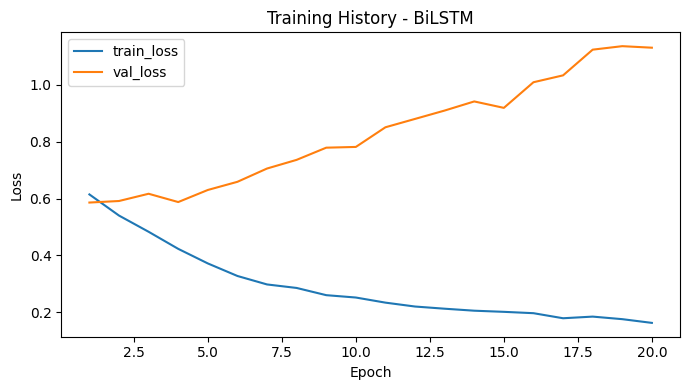

Best threshold BiLSTM berdasarkan validation F1: 0.41999999999999993 F1: 0.7368421052631579
model            BiLSTM
threshold          0.42
accuracy        0.65917
precision         0.625
recall         0.819113
specificity    0.494737
f1              0.70901
roc_auc        0.727789
pr_auc          0.72204
dtype: object

Confusion Matrix:
[[141 144]
 [ 53 240]]

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.49      0.59       285
           1       0.62      0.82      0.71       293

    accuracy                           0.66       578
   macro avg       0.68      0.66      0.65       578
weighted avg       0.68      0.66      0.65       578



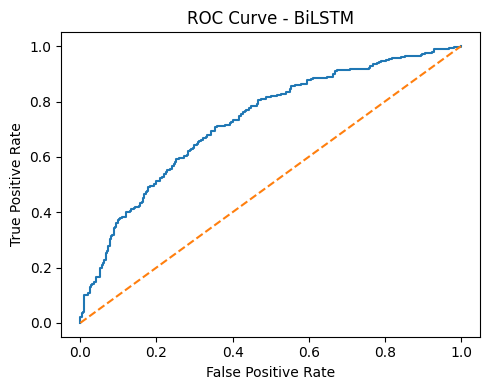

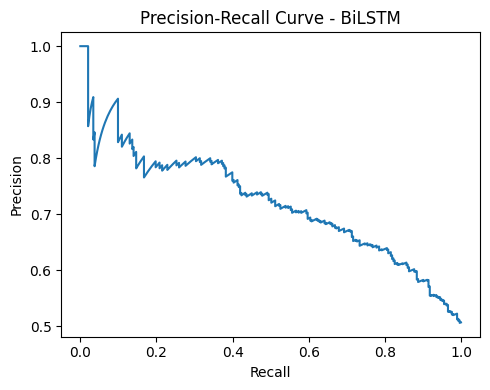

In [25]:
bilstm_model = LSTMClassifier(
    input_size=input_size,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT,
    bidirectional=True
)

bilstm_model, bilstm_history = train_torch_model(
    bilstm_model,
    train_loader,
    val_loader,
    y_train,
    epochs=EPOCHS,
    lr=LEARNING_RATE,
    use_class_weight=USE_CLASS_WEIGHT,
    use_focal_loss=USE_FOCAL_LOSS,
    focal_gamma=FOCAL_GAMMA
)

plot_training_history(bilstm_history, "Training History - BiLSTM")

y_val_bilstm, bilstm_val_prob = predict_torch_model(bilstm_model, val_loader)
y_test_bilstm, bilstm_test_prob = predict_torch_model(bilstm_model, test_loader)

bilstm_best_th, bilstm_best_score = find_best_threshold(y_val_bilstm, bilstm_val_prob, metric="f1")
print("Best threshold BiLSTM berdasarkan validation F1:", bilstm_best_th, "F1:", bilstm_best_score)

bilstm_metrics, bilstm_cm, bilstm_pred = print_evaluation(
    y_test,
    bilstm_test_prob,
    threshold=bilstm_best_th,
    label="BiLSTM"
)

plot_roc_pr_curves(y_test, bilstm_test_prob, title="BiLSTM")

## 23. Perbandingan Hasil Model
Bagian ini menggabungkan hasil evaluasi semua model.

,model,threshold,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc
1,LSTM,0.43,0.662630,0.629630,0.812287,0.508772,0.709389,0.738375,0.736551
2,BiLSTM,0.42,0.659170,0.625000,0.819113,0.494737,0.709010,0.727789,0.722040
0,Random Forest Baseline,0.50,0.681661,0.683502,0.692833,0.670175,0.688136,0.735249,0.724597


<Figure size 800x400 with 0 Axes>

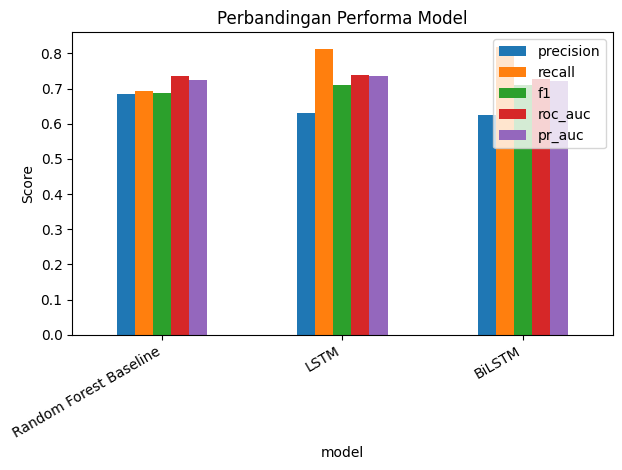

In [26]:
results = pd.DataFrame([rf_metrics, lstm_metrics, bilstm_metrics])
display(results.sort_values("f1", ascending=False))

plt.figure(figsize=(8, 4))
results.set_index("model")[["precision", "recall", "f1", "roc_auc", "pr_auc"]].plot(kind="bar")
plt.ylabel("Score")
plt.title("Perbandingan Performa Model")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# 24. XAI Awal

Untuk tahap awal, notebook ini menyediakan dua pendekatan interpretasi:

1. **Permutation importance pada baseline Random Forest**
   - membantu melihat fitur mana yang paling berpengaruh setelah sequence diratakan.

2. **Temporal perturbation importance untuk LSTM/BiLSTM**
   - membantu melihat timestep/refill keberapa yang paling berpengaruh terhadap prediksi model.

## 24.1 XAI Baseline: Permutation Importance Random Forest
Karena fitur sequence diratakan, nama fitur dibuat dalam format:

```text
t1_gap_days
t2_gap_days
...
```

,feature,importance_mean,importance_std
5,t1_mean_TOTAL AMOUNT PAID,0.009951,0.002614
2059,t3_mean_AMOUNT CLAIMED,0.007978,0.002845
1033,t2_mean_TOTAL AMOUNT PAID,0.007421,0.003613
4,t1_sum_TOTAL AMOUNT PAID,0.006752,0.004691
3,t1_mean_AMOUNT CLAIMED,0.006312,0.005366
8,t1_mean_CURRENT AGE,0.006283,0.004328
2060,t3_sum_TOTAL AMOUNT PAID,0.006132,0.003449
2064,t3_mean_CURRENT AGE,0.005999,0.004478
1031,t2_mean_AMOUNT CLAIMED,0.005609,0.001006
2,t1_sum_AMOUNT CLAIMED,0.004294,0.002967


<Figure size 800x600 with 0 Axes>

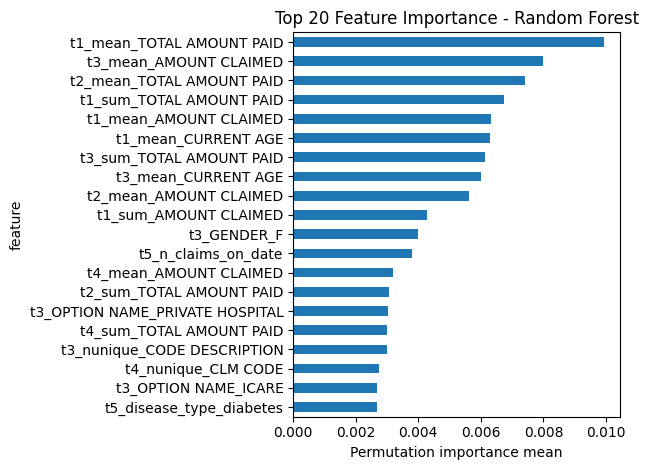

In [27]:
flat_feature_names = []
for t in range(MAX_SEQ_LEN):
    for feat in feature_cols:
        flat_feature_names.append(f"t{t+1}_{feat}")

perm = permutation_importance(
    rf,
    X_test_flat,
    y_test,
    n_repeats=5,
    random_state=RANDOM_STATE,
    scoring="f1",
    n_jobs=-1
)

perm_df = pd.DataFrame({
    "feature": flat_feature_names,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

display(perm_df.head(20))

plt.figure(figsize=(8, 6))
perm_df.head(20).sort_values("importance_mean").plot(
    x="feature",
    y="importance_mean",
    kind="barh",
    legend=False
)
plt.xlabel("Permutation importance mean")
plt.title("Top 20 Feature Importance - Random Forest")
plt.tight_layout()
plt.show()

## 24.2 XAI Temporal Importance untuk LSTM/BiLSTM
Pendekatan ini mengukur pengaruh setiap timestep dengan cara:
- memilih satu timestep,
- mengganti fitur pada timestep tersebut menjadi nol,
- melihat perubahan probabilitas prediksi.

Semakin besar perubahan probabilitas, semakin penting timestep tersebut.

,timestep,LSTM_importance,BiLSTM_importance
0,1,0.019068,0.041191
1,2,0.028802,0.034438
2,3,0.038001,0.035627
3,4,0.044846,0.040037
4,5,0.052568,0.047292
5,6,0.065539,0.059960


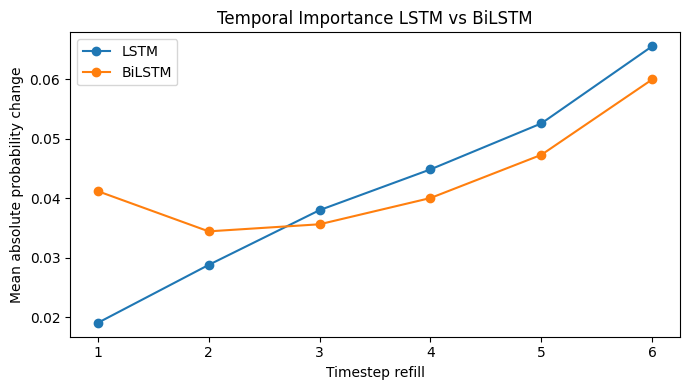

In [28]:
def temporal_perturbation_importance(model, X_data, baseline_prob=None):
    if baseline_prob is None:
        temp_dataset = SequenceDataset(X_data, np.zeros(X_data.shape[0]))
        temp_loader = DataLoader(temp_dataset, batch_size=BATCH_SIZE, shuffle=False)
        _, baseline_prob = predict_torch_model(model, temp_loader)

    importances = []

    for t in range(X_data.shape[1]):
        X_perturbed = X_data.copy()
        X_perturbed[:, t, :] = 0

        temp_dataset = SequenceDataset(X_perturbed, np.zeros(X_perturbed.shape[0]))
        temp_loader = DataLoader(temp_dataset, batch_size=BATCH_SIZE, shuffle=False)
        _, perturbed_prob = predict_torch_model(model, temp_loader)

        mean_abs_change = np.mean(np.abs(baseline_prob - perturbed_prob))
        importances.append(mean_abs_change)

    return np.array(importances)

lstm_temporal_importance = temporal_perturbation_importance(
    lstm_model,
    X_test_scaled,
    baseline_prob=lstm_test_prob
)

bilstm_temporal_importance = temporal_perturbation_importance(
    bilstm_model,
    X_test_scaled,
    baseline_prob=bilstm_test_prob
)

temporal_df = pd.DataFrame({
    "timestep": np.arange(1, MAX_SEQ_LEN + 1),
    "LSTM_importance": lstm_temporal_importance,
    "BiLSTM_importance": bilstm_temporal_importance
})

display(temporal_df)

plt.figure(figsize=(7, 4))
plt.plot(temporal_df["timestep"], temporal_df["LSTM_importance"], marker="o", label="LSTM")
plt.plot(temporal_df["timestep"], temporal_df["BiLSTM_importance"], marker="o", label="BiLSTM")
plt.xlabel("Timestep refill")
plt.ylabel("Mean absolute probability change")
plt.title("Temporal Importance LSTM vs BiLSTM")
plt.legend()
plt.tight_layout()
plt.show()

## 24.3 Feature Perturbation Importance untuk LSTM/BiLSTM
Pendekatan ini mengukur pengaruh fitur dengan cara meniadakan satu fitur pada seluruh timestep.

Top 20 LSTM feature importance:


,feature,importance
13,event_index,0.017047
10,nunique_CODE DESCRIPTION,0.015663
9,nunique_CLM CODE,0.014724
11,nunique_PROVIDER,0.014379
15,days_since_first,0.013256
1026,disease_type_diabetes,0.012572
8,mean_CURRENT AGE,0.012187
12,n_claims_on_date,0.009744
1,mean_UNITS,0.009335
0,sum_UNITS,0.008277


Top 20 BiLSTM feature importance:


,feature,importance
11,nunique_PROVIDER,0.010818
1026,disease_type_diabetes,0.010777
12,n_claims_on_date,0.009963
411,PAYER NAME_INDIVIDUAL ON CORPORATES,0.009576
9,nunique_CLM CODE,0.009352
13,event_index,0.009285
0,sum_UNITS,0.008459
15,days_since_first,0.007469
1,mean_UNITS,0.007316
4,sum_TOTAL AMOUNT PAID,0.007278


<Figure size 800x600 with 0 Axes>

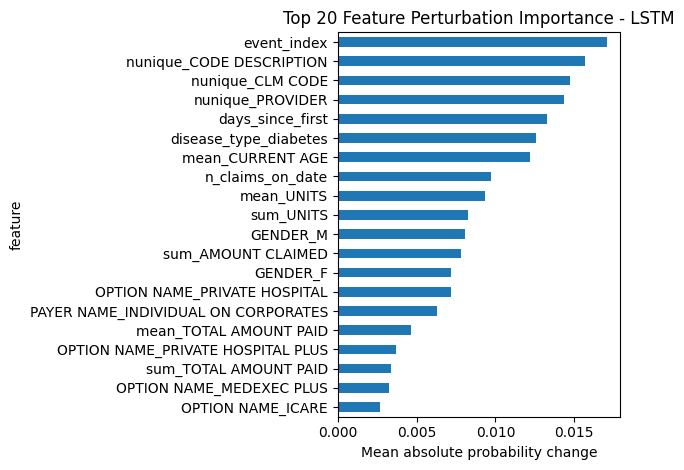

<Figure size 800x600 with 0 Axes>

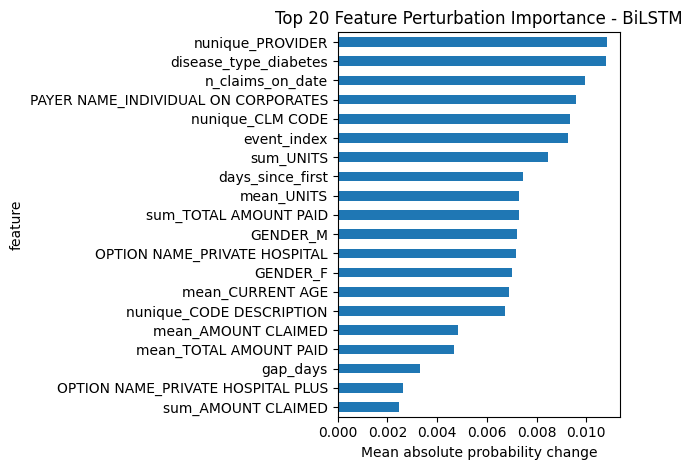

In [29]:
def sequence_feature_perturbation_importance(model, X_data, feature_cols, baseline_prob=None):
    if baseline_prob is None:
        temp_dataset = SequenceDataset(X_data, np.zeros(X_data.shape[0]))
        temp_loader = DataLoader(temp_dataset, batch_size=BATCH_SIZE, shuffle=False)
        _, baseline_prob = predict_torch_model(model, temp_loader)

    importances = []

    for j, feat in enumerate(feature_cols):
        X_perturbed = X_data.copy()
        X_perturbed[:, :, j] = 0

        temp_dataset = SequenceDataset(X_perturbed, np.zeros(X_perturbed.shape[0]))
        temp_loader = DataLoader(temp_dataset, batch_size=BATCH_SIZE, shuffle=False)
        _, perturbed_prob = predict_torch_model(model, temp_loader)

        mean_abs_change = np.mean(np.abs(baseline_prob - perturbed_prob))
        importances.append((feat, mean_abs_change))

    return pd.DataFrame(importances, columns=["feature", "importance"]).sort_values("importance", ascending=False)

lstm_feature_imp = sequence_feature_perturbation_importance(
    lstm_model,
    X_test_scaled,
    feature_cols,
    baseline_prob=lstm_test_prob
)

bilstm_feature_imp = sequence_feature_perturbation_importance(
    bilstm_model,
    X_test_scaled,
    feature_cols,
    baseline_prob=bilstm_test_prob
)

print("Top 20 LSTM feature importance:")
display(lstm_feature_imp.head(20))

print("Top 20 BiLSTM feature importance:")
display(bilstm_feature_imp.head(20))

plt.figure(figsize=(8, 6))
lstm_feature_imp.head(20).sort_values("importance").plot(
    x="feature",
    y="importance",
    kind="barh",
    legend=False
)
plt.xlabel("Mean absolute probability change")
plt.title("Top 20 Feature Perturbation Importance - LSTM")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
bilstm_feature_imp.head(20).sort_values("importance").plot(
    x="feature",
    y="importance",
    kind="barh",
    legend=False
)
plt.xlabel("Mean absolute probability change")
plt.title("Top 20 Feature Perturbation Importance - BiLSTM")
plt.tight_layout()
plt.show()

# 25. Simpan Hasil Eksperimen
Bagian ini menyimpan hasil evaluasi dan importance ke file CSV agar bisa digunakan untuk penulisan tesis.

In [30]:
OUTPUT_DIR = Path("outputs_adherence")
OUTPUT_DIR.mkdir(exist_ok=True)

results.to_csv(OUTPUT_DIR / "model_comparison_results.csv", index=False)
perm_df.to_csv(OUTPUT_DIR / "rf_permutation_importance.csv", index=False)
temporal_df.to_csv(OUTPUT_DIR / "lstm_bilstm_temporal_importance.csv", index=False)
lstm_feature_imp.to_csv(OUTPUT_DIR / "lstm_feature_importance.csv", index=False)
bilstm_feature_imp.to_csv(OUTPUT_DIR / "bilstm_feature_importance.csv", index=False)

print("Hasil eksperimen tersimpan di folder:", OUTPUT_DIR.resolve())

Hasil eksperimen tersimpan di folder: /Users/riskyduha/Documents/Tesis/Prediction_Non_Adherent/outputs_adherence


# 26. Rekomendasi Eksperimen Lanjutan untuk Tesis

Setelah notebook ini berhasil dijalankan, Anda dapat melakukan variasi eksperimen berikut:

## Variasi Dataset
1. Diabetes saja
2. HTN saja
3. Gabungan Diabetes + HTN

## Variasi Panjang Sequence
1. `MAX_SEQ_LEN = 3`
2. `MAX_SEQ_LEN = 6`
3. `MAX_SEQ_LEN = 9`
4. `MAX_SEQ_LEN = 12`

## Variasi Label
1. Standard non-adherence: `ADHERENCE < 9`
2. Severe non-adherence: `ADHERENCE <= 3`
3. Severe non-adherence lebih ketat: `ADHERENCE <= 2`

## Variasi Model
1. Random Forest baseline
2. LSTM
3. BiLSTM
4. LSTM + class weight
5. BiLSTM + class weight
6. LSTM + focal loss
7. BiLSTM + focal loss

## Variasi XAI
1. Permutation importance
2. Temporal perturbation importance
3. Feature perturbation importance
4. SHAP untuk baseline model
5. Attention-based model sebagai pengembangan berikutnya

## Catatan Metodologis Penting
Untuk framing tesis, disarankan menggunakan `SEQUENCE_MODE = "first"` agar penelitian terlihat sebagai prediksi prospektif:
- gunakan refill awal pasien,
- prediksi status kepatuhan akhir.

Hal ini lebih kuat dibanding memakai seluruh riwayat refill karena dapat mengurangi risiko data leakage.